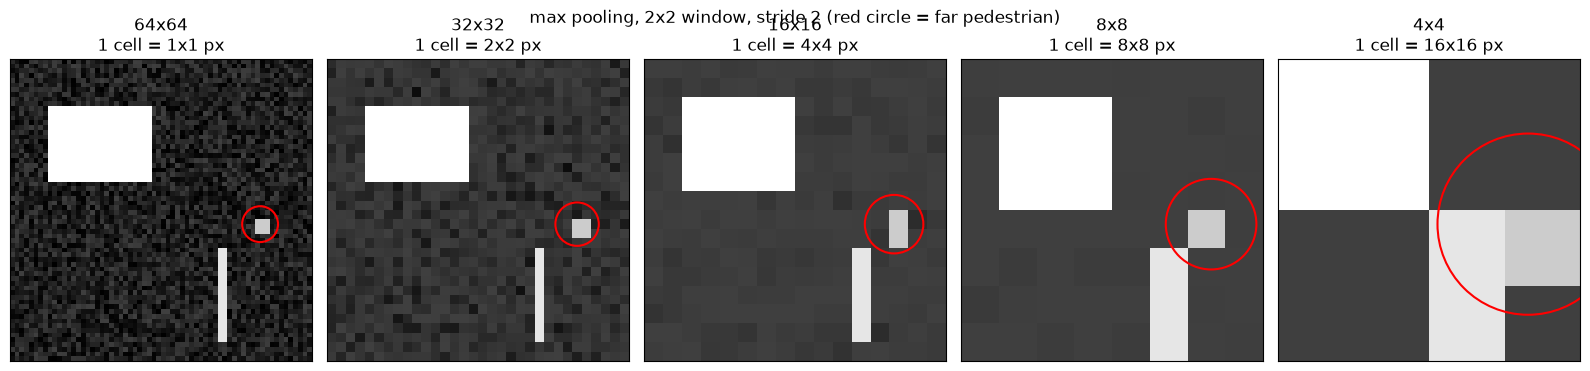

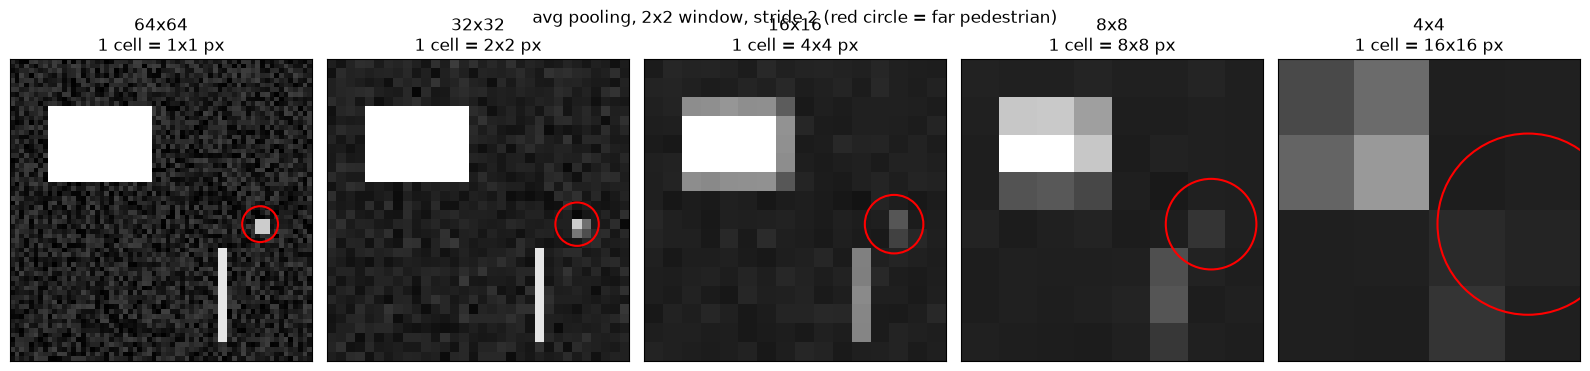

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# --- Make a synthetic 64x64 "road scene" ---
rng = np.random.default_rng(0)
img = rng.uniform(0.0, 0.25, size=(64, 64))  # noisy background

img[10:26, 8:30] = 1.0      # big object (a "car")
img[40:60, 44:46] = 0.9     # thin line (a "lane mark")
img[34:37, 52:55] = 0.8     # tiny object, 3x3 pixels (a "far pedestrian")
PED = (35, 53)              # pedestrian centre (row, col) in original pixels


def pool2x2(x, mode="max"):
    """Pool with a 2x2 window, stride 2. Map size halves."""
    h, w = x.shape
    blocks = x.reshape(h // 2, 2, w // 2, 2)
    if mode == "max":
        return blocks.max(axis=(1, 3))
    return blocks.mean(axis=(1, 3))


def run(mode):
    maps = [img]
    for _ in range(4):
        maps.append(pool2x2(maps[-1], mode))
    return maps


def show(mode):
    maps = run(mode)
    fig, axes = plt.subplots(1, len(maps), figsize=(16, 3.8))
    for i, (ax, m) in enumerate(zip(axes, maps)):
        size = m.shape[0]
        cell = 64 // size
        ax.imshow(m, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        # mark where the pedestrian is, in this map's coordinates
        r, c = PED[0] / cell, PED[1] / cell
        ax.add_patch(plt.Circle((c - 0.5, r - 0.5), max(1.2, 3 / cell + 0.8),
                                fill=False, color="red", lw=1.5))
        ax.set_title(f"{size}x{size}\n1 cell = {cell}x{cell} px")
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(f"{mode} pooling, 2x2 window, stride 2 (red circle = far pedestrian)")
    plt.tight_layout()
    plt.show()


show("max")
show("avg")